## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from torch import nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)

df = pd.read_csv("monthly_milk_production.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df.head()

,Date,Production
0,1962-01-01,589
1,1962-02-01,561
2,1962-03-01,640
3,1962-04-01,656
4,1962-05-01,727


In [2]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (168, 2)

Data types:
Date          datetime64[ns]
Production             int64
dtype: object

Missing values:
Date          0
Production    0
dtype: int64

Duplicate rows: 0


In [3]:
df.describe()

,Date,Production
count,168,168.000000
mean,1968-12-15 16:17:08.571428572,754.708333
min,1962-01-01 00:00:00,553.000000
25%,1965-06-23 12:00:00,677.750000
50%,1968-12-16 12:00:00,761.000000
75%,1972-06-08 12:00:00,824.500000
max,1975-12-01 00:00:00,969.000000
std,NaN,102.204524


## 2. Exploratory data analysis

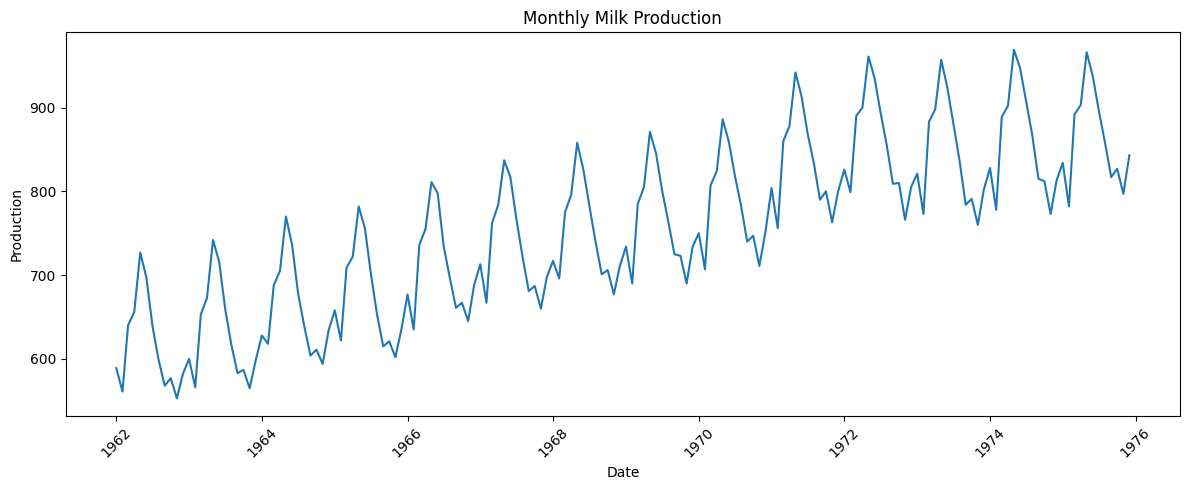

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Production"])
plt.title("Monthly Milk Production")
plt.xlabel("Date")
plt.ylabel("Production")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

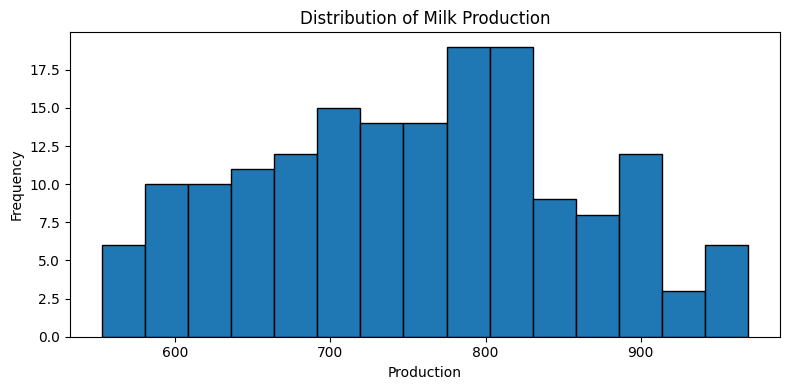

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(df["Production"], bins=15, edgecolor="black")
plt.title("Distribution of Milk Production")
plt.xlabel("Production")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

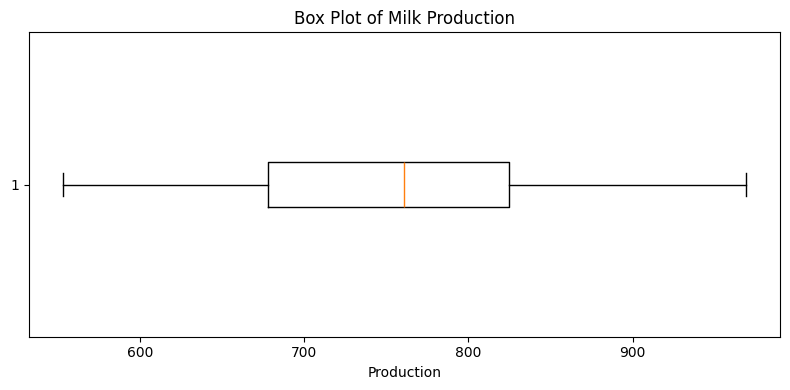

Possible outliers by the IQR rule: 0


,Date,Production


In [6]:
plt.figure(figsize=(8, 4))
plt.boxplot(df["Production"], vert=False)
plt.title("Box Plot of Milk Production")
plt.xlabel("Production")
plt.tight_layout()
plt.show()

q1 = df["Production"].quantile(0.25)
q3 = df["Production"].quantile(0.75)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr
outliers = df[(df["Production"] < lower_limit) | (df["Production"] > upper_limit)]
print("Possible outliers by the IQR rule:", len(outliers))
outliers.head()

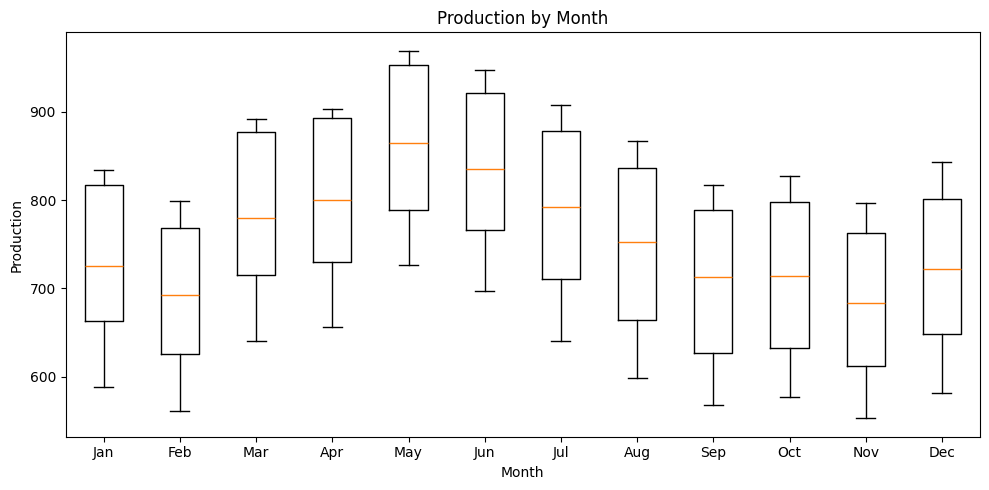

In [7]:
df["Month"] = df["Date"].dt.month
monthly_values = [df.loc[df["Month"] == month, "Production"].values for month in range(1, 13)]

plt.figure(figsize=(10, 5))
plt.boxplot(monthly_values, tick_labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.title("Production by Month")
plt.xlabel("Month")
plt.ylabel("Production")
plt.tight_layout()
plt.show()

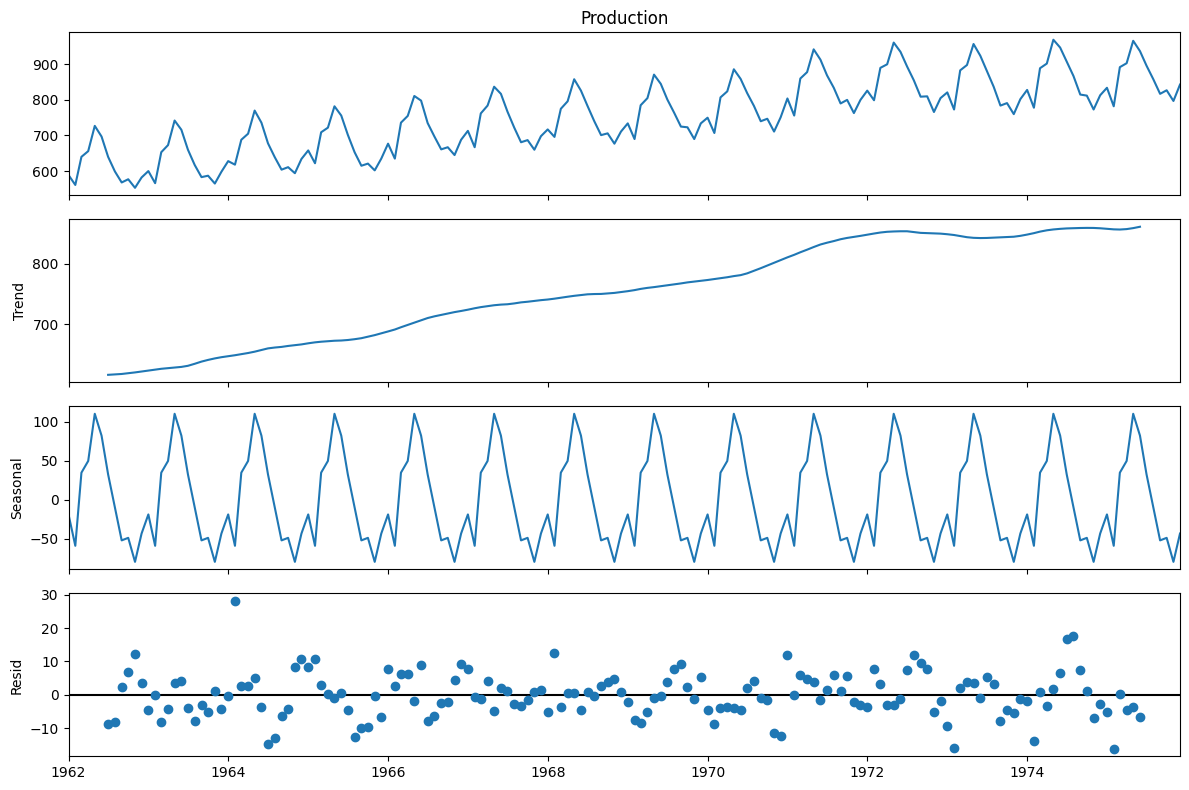

In [8]:
decomposition = seasonal_decompose(df.set_index("Date")["Production"], model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

## 3. Prepare the data for the models

The rows are kept in date order. The first 70% is used for training, the next 15% for validation, and the final 15% for testing. A 12-month input window is used so that each prediction can use the previous year of production. The scaler is fitted only on training observations.

In [9]:
production = df["Production"].to_numpy(dtype=float)
dates = df["Date"].copy()
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
window = 12

scaler = MinMaxScaler()
scaler.fit(production[:train_end].reshape(-1, 1))
scaled_production = scaler.transform(production.reshape(-1, 1))

print("Total observations:", n)
print("Training observations:", train_end)
print("Validation observations:", val_end - train_end)
print("Testing observations:", n - val_end)
print("Input window:", window)

Total observations: 168
Training observations: 117
Validation observations: 25
Testing observations: 26
Input window: 12


In [10]:
def create_sequences(values, window_size):
    X, y, positions = [], [], []
    for i in range(window_size, len(values)):
        X.append(values[i - window_size:i, 0])
        y.append(values[i, 0])
        positions.append(i)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), np.array(positions)

X_all, y_all, positions = create_sequences(scaled_production, window)
train_mask = positions < train_end
val_mask = (positions >= train_end) & (positions < val_end)
test_mask = positions >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

X_train: (105, 12) y_train: (105,)
X_val: (25, 12) y_val: (25,)
X_test: (26, 12) y_test: (26,)


## 4. Build RNN, LSTM and GRU models

In [11]:
class ForecastModel(nn.Module):
    def __init__(self, model_type, hidden_size):
        super().__init__()
        self.model_type = model_type
        if model_type == "RNN":
            self.recurrent = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        else:
            self.recurrent = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        result = self.recurrent(x)
        sequence_output = result[0]
        return self.output(sequence_output[:, -1, :])


def fit_model(model_type, hidden_size, X, y, epochs=100, learning_rate=0.01):
    torch.manual_seed(42)
    model = ForecastModel(model_type, hidden_size)
    X_tensor = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
    y_tensor = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_function = nn.MSELoss()

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        predictions = model(X_tensor)
        loss = loss_function(predictions, y_tensor)
        loss.backward()
        optimizer.step()
    return model


def predict_model(model, X):
    model.eval()
    X_tensor = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
    with torch.no_grad():
        predictions = model(X_tensor).cpu().numpy().reshape(-1)
    return predictions


def inverse_scale(values, fitted_scaler):
    return fitted_scaler.inverse_transform(np.asarray(values).reshape(-1, 1)).reshape(-1)


def get_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    return mae, rmse, mape

## 5. Hyperparameter tuning


In [12]:
hidden_options = [8, 16, 32]
model_types = ["RNN", "LSTM", "GRU"]
tuning_results = []

for model_type in model_types:
    for hidden_size in hidden_options:
        model = fit_model(model_type, hidden_size, X_train, y_train, epochs=100, learning_rate=0.01)
        val_scaled_pred = predict_model(model, X_val)
        val_pred = inverse_scale(val_scaled_pred, scaler)
        val_actual = inverse_scale(y_val, scaler)
        val_rmse = np.sqrt(mean_squared_error(val_actual, val_pred))
        tuning_results.append({"Model": model_type, "Hidden units": hidden_size, "Validation RMSE": val_rmse})

tuning_df = pd.DataFrame(tuning_results).sort_values(["Model", "Validation RMSE"]).reset_index(drop=True)
tuning_df

,Model,Hidden units,Validation RMSE
0,GRU,8,36.191932
1,GRU,32,38.337784
2,GRU,16,45.809580
3,LSTM,32,42.763299
4,LSTM,16,43.800941
5,LSTM,8,48.775614
6,RNN,32,29.142157
7,RNN,8,30.835519
8,RNN,16,42.953334


In [13]:
best_rows = tuning_df.loc[tuning_df.groupby("Model")["Validation RMSE"].idxmin()]
best_hidden_sizes = dict(zip(best_rows["Model"], best_rows["Hidden units"]))
print("Selected hidden units:", best_hidden_sizes)
best_rows.reset_index(drop=True)

Selected hidden units: {'GRU': 8, 'LSTM': 32, 'RNN': 32}


,Model,Hidden units,Validation RMSE
0,GRU,8,36.191932
1,LSTM,32,42.763299
2,RNN,32,29.142157


## 6. Evaluate the models on the test set

For the final test comparison, each model is trained on the training and validation periods. The final test period stays separate and is not used for model selection.

In [14]:
train_val_mask = positions < val_end
X_train_val = X_all[train_val_mask]
y_train_val = y_all[train_val_mask]
actual_test = inverse_scale(y_test, scaler)

baseline_results = []
tuned_results = []
test_predictions = {}

for model_type in model_types:
    baseline_model = fit_model(model_type, 16, X_train_val, y_train_val, epochs=120, learning_rate=0.01)
    baseline_scaled = predict_model(baseline_model, X_test)
    baseline_pred = inverse_scale(baseline_scaled, scaler)
    baseline_mae, baseline_rmse, baseline_mape = get_metrics(actual_test, baseline_pred)
    baseline_results.append({"Model": model_type, "MAE": baseline_mae, "RMSE": baseline_rmse, "MAPE (%)": baseline_mape})

    tuned_model = fit_model(model_type, best_hidden_sizes[model_type], X_train_val, y_train_val, epochs=120, learning_rate=0.01)
    tuned_scaled = predict_model(tuned_model, X_test)
    tuned_pred = inverse_scale(tuned_scaled, scaler)
    test_predictions[model_type] = tuned_pred
    tuned_mae, tuned_rmse, tuned_mape = get_metrics(actual_test, tuned_pred)
    tuned_results.append({"Model": model_type, "Hidden units": best_hidden_sizes[model_type], "MAE": tuned_mae, "RMSE": tuned_rmse, "MAPE (%)": tuned_mape})

baseline_df = pd.DataFrame(baseline_results).round(3)
tuned_df = pd.DataFrame(tuned_results).round(3)
print("Default models (16 hidden units):")
display(baseline_df)
print("Tuned models:")
display(tuned_df)

Default models (16 hidden units):


,Model,MAE,RMSE,MAPE (%)
0,RNN,33.798,41.354,3.928
1,LSTM,27.447,36.619,3.231
2,GRU,33.703,42.538,3.939


Tuned models:


,Model,Hidden units,MAE,RMSE,MAPE (%)
0,RNN,32,24.515,27.180,2.924
1,LSTM,32,24.742,32.510,2.913
2,GRU,8,22.470,32.098,2.675


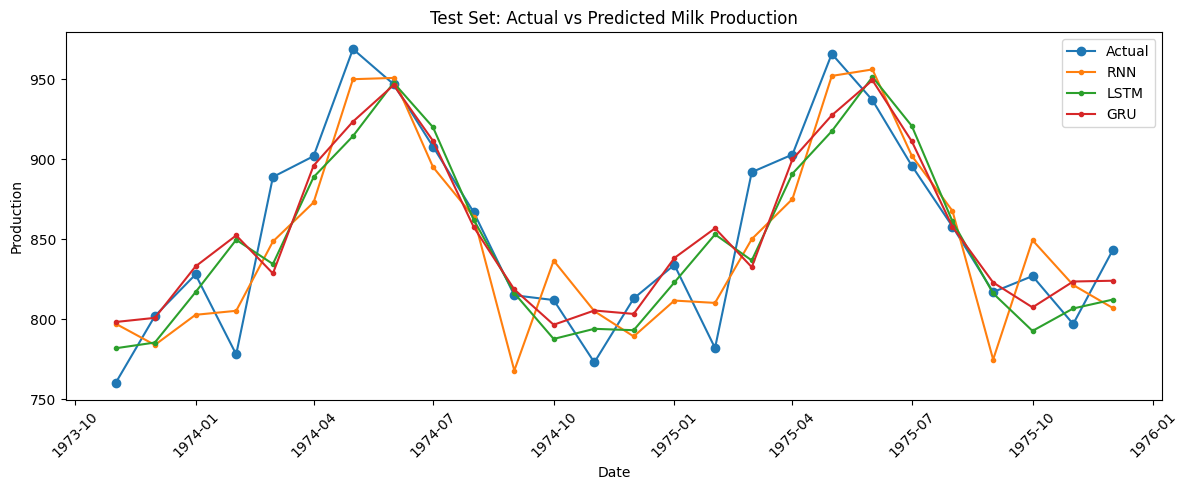

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(dates.iloc[val_end:], actual_test, marker="o", label="Actual")
for model_type in model_types:
    plt.plot(dates.iloc[val_end:], test_predictions[model_type], marker=".", label=model_type)
plt.title("Test Set: Actual vs Predicted Milk Production")
plt.xlabel("Date")
plt.ylabel("Production")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
best_test_model = tuned_df.loc[tuned_df["RMSE"].idxmin(), "Model"]
print("Model with the lowest test RMSE:", best_test_model)
print("Test period:", dates.iloc[val_end].date(), "to", dates.iloc[-1].date())

Model with the lowest test RMSE: RNN
Test period: 1973-11-01 to 1975-12-01


## 7. Forecast the next 12 months

For the future forecast, each selected model is retrained on all available observations. An approximate range between the three model forecasts is also shown. This range represents model disagreement, not a formal statistical confidence interval.

In [17]:
full_scaler = MinMaxScaler()
full_scaled = full_scaler.fit_transform(production.reshape(-1, 1))
X_full, y_full, full_positions = create_sequences(full_scaled, window)

future_dates = pd.date_range(dates.iloc[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
future_forecasts = {}

for model_type in model_types:
    final_model = fit_model(model_type, best_hidden_sizes[model_type], X_full, y_full, epochs=150, learning_rate=0.01)
    last_window = full_scaled[-window:].reshape(1, window, 1).astype(np.float32)
    predicted_scaled = []

    final_model.eval()
    for step in range(12):
        with torch.no_grad():
            next_value = final_model(torch.tensor(last_window, dtype=torch.float32)).cpu().numpy().reshape(-1)[0]
        predicted_scaled.append(next_value)
        last_window = np.concatenate([last_window[:, 1:, :], np.array(next_value, dtype=np.float32).reshape(1, 1, 1)], axis=1)

    future_forecasts[model_type] = inverse_scale(predicted_scaled, full_scaler)

forecast_df = pd.DataFrame({"Date": future_dates, **future_forecasts})
forecast_df.round(2)

,Date,RNN,LSTM,GRU
0,1976-01-01,818.849976,830.500000,837.799988
1,1976-02-01,816.090027,846.849976,835.650024
2,1976-03-01,843.179993,871.570007,859.789978
3,1976-04-01,872.960022,893.669983,872.549988
4,1976-05-01,925.330017,910.349976,891.659973
5,1976-06-01,932.289978,909.179993,890.690002
6,1976-07-01,924.270020,892.169983,875.359985
7,1976-08-01,880.789978,866.059998,850.229980
8,1976-09-01,838.820007,840.409973,822.609985
9,1976-10-01,827.200012,823.479980,810.280029


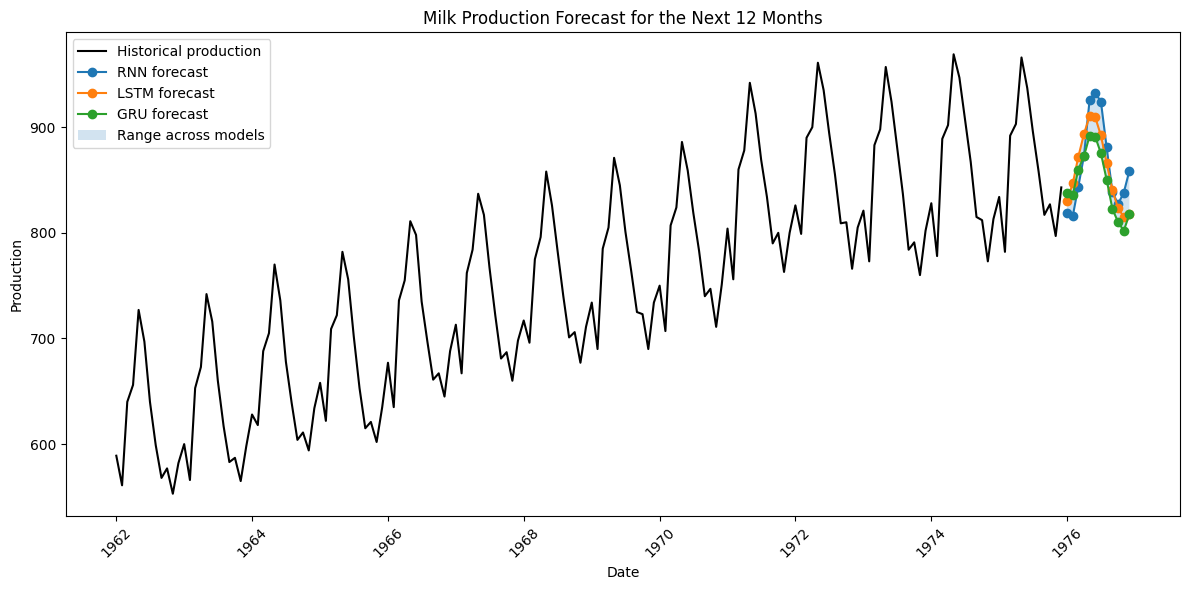

In [18]:
plt.figure(figsize=(12, 6))
plt.plot(dates, production, label="Historical production", color="black")
for model_type in model_types:
    plt.plot(future_dates, future_forecasts[model_type], marker="o", label=f"{model_type} forecast")
forecast_matrix = np.column_stack([future_forecasts[name] for name in model_types])
plt.fill_between(future_dates, forecast_matrix.min(axis=1), forecast_matrix.max(axis=1), alpha=0.2, label="Range across models")
plt.title("Milk Production Forecast for the Next 12 Months")
plt.xlabel("Date")
plt.ylabel("Production")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Findings and business insights

- The time-series plots and monthly box plots can be used to check the long-term trend and annual seasonal changes.
- The three models are compared on the same chronological test period using MAE, RMSE and MAPE. Lower values mean smaller forecast errors.
- A 12-month input window gives the networks one full cycle of monthly history, while the validation period is used to choose the number of hidden units.
- The 12-month future forecast can support production, storage, distribution and staffing plans. It should be updated as new monthly values arrive because the series is relatively short and the forecasts become less certain further into the future.

The shaded range in the forecast chart shows the spread between model outputs. It is a simple indication of model disagreement, not a guaranteed confidence interval.